In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import  KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np 
from sklearn.linear_model import LogisticRegression  # Swapped to Logistic
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score , classification_report,mean_absolute_error , precision_score , recall_score , f1_score , confusion_matrix ,r2_score


In [11]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
df  = df.dropna()


df['gender'] = df['gender'].apply(
    lambda x: 0 if str(x).strip().lower() == 'male' else 1
)


df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.iloc[:, 0:-1]
y = df_encoded.iloc[:, -1]


## Logistic Regression

In [12]:

# X = df.iloc[:,0:-1]
# y = df.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.3,random_state=30)

LRmodel = LogisticRegression(max_iter=500)

LRmodel.fit(X_train,y_train)
LRy_pred = LRmodel.predict(X_test)


LRaccuracy = accuracy_score(LRy_pred,y_test)*100
LRaccuracytrain = accuracy_score(LRmodel.predict(X_train),y_train) *100

print(f"accuracy Score : {LRaccuracy}")

print(f"accuracy Score Training: {LRaccuracytrain}")

LRcm = confusion_matrix(LRy_pred,y_test)
print(LRcm)
print(f"Correctly guessed No Diabetes (True Negatives): {LRcm[0][0]}")
print(f"Wrongly guessed Diabetes (False Positives): {LRcm[0][1]}")
print(f"Wrongly guessed No Diabetes (False Negatives): {LRcm[1][0]}")
print(f"Correctly guessed Diabetes (True Positives): {LRcm[1][1]}")
print(classification_report(y_test, LRy_pred))
# X.head(15)

accuracy Score : 93.61333333333334
accuracy Score Training: 93.51428571428572
[[28078  1908]
 [    8     6]]
Correctly guessed No Diabetes (True Negatives): 28078
Wrongly guessed Diabetes (False Positives): 1908
Wrongly guessed No Diabetes (False Negatives): 8
Correctly guessed Diabetes (True Positives): 6
              precision    recall  f1-score   support

       False       0.94      1.00      0.97     28086
        True       0.43      0.00      0.01      1914

    accuracy                           0.94     30000
   macro avg       0.68      0.50      0.49     30000
weighted avg       0.90      0.94      0.91     30000



c:\Users\Zain\Desktop\jbooks\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Results:
**Accuracy Score is 93.6% and also close to the accuracy score of training data that is 93.5%**

## KNN

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler  

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.3,random_state=30)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


KnnModel = KNeighborsClassifier(n_neighbors=5)


KnnModel.fit(X_train_scaled, y_train)


Knny_pred = KnnModel.predict(X_test_scaled)

KnnAccuracy = accuracy_score(Knny_pred,y_test) * 100
KnnTrainingAccuracy = accuracy_score(KnnModel.predict(X_train_scaled),y_train) * 100

print(f"Accuracy Score:{KnnAccuracy}")

print(f"Training Accuacy Score:{KnnTrainingAccuracy}")


Accuracy Score:92.67999999999999
Training Accuacy Score:94.24571428571429


### Results:
**Accuracy Score is good 92.68% and also close to the accuracy score of training data that is 94.2%**

# Random Forest Classifier

In [14]:
from sklearn.ensemble import RandomForestClassifier as rfc 

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.3,random_state=30)

rfc_model = rfc(n_estimators=100, random_state=40)
rfc_model.fit(X_train,y_train)

rfcy_pred = rfc_model.predict(X_test)

rfcAccuracy = accuracy_score(rfcy_pred,y_test) *100

rfcTrainingAccuracy = accuracy_score(rfc_model.predict(X_train),y_train) *100

print(f"RFC Accuracy Score:{rfcAccuracy}")
print(f"RFC raining Data Accuracy Score:{rfcTrainingAccuracy}")

print(
rfc_model.feature_importances_
)


RFC Accuracy Score:92.70333333333333
RFC raining Data Accuracy Score:99.47571428571429
[0.01143065 0.28312998 0.00664512 0.00580091 0.27218373 0.1365502
 0.15233945 0.00368872 0.02336738 0.01428173 0.0267421  0.06384002]


### Results:
**Accuracy Score is 92.7% and also close to the accuracy score of training data that is 99.47%**

# Deep Learning Model ,Sequential

In [17]:
import tensorflow as tf 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.3,random_state=30)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

seq_model = Sequential()

seq_model.add(Dense(10,activation="relu",input_dim =(X_train_scaled.shape[1])))
seq_model.add(Dense(23,activation="relu"))
seq_model.add(Dense(1,activation="sigmoid"))

seq_model.compile(
    optimizer= "adam",
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

history = seq_model.fit(X_train_scaled,y_train,epochs=4,batch_size=12,validation_data=(X_test_scaled,y_test))
loss ,seq_accuracy = seq_model.evaluate(X_test_scaled,y_test) 
seq_accuracy= seq_accuracy*100
print(seq_accuracy)



Epoch 1/4


c:\Users\Zain\Desktop\jbooks\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5834/5834 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9318 - loss: 0.1850 - val_accuracy: 0.9362 - val_loss: 0.1676
Epoch 2/4
5834/5834 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9352 - loss: 0.1677 - val_accuracy: 0.9362 - val_loss: 0.1652
Epoch 3/4
5834/5834 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.9352 - loss: 0.1667 - val_accuracy: 0.9363 - val_loss: 0.1647
Epoch 4/4
5834/5834 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step - accuracy: 0.9352 - loss: 0.1663 - val_accuracy: 0.9361 - val_loss: 0.1643
938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9361 - loss: 0.1643
93.6133325099945


### Results:
**Accuracy Score is 93.6% on testing data**

### Graphical Comparision of accuracies of different Models

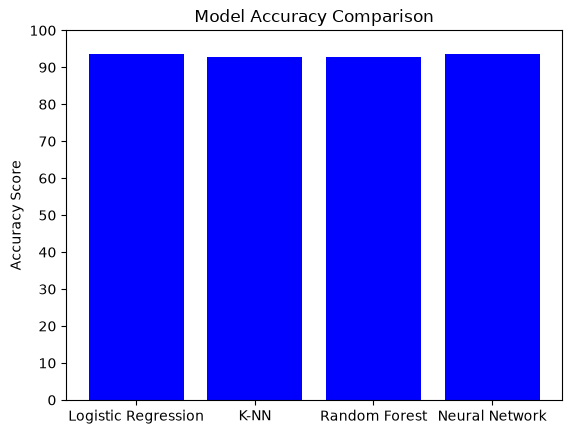

In [22]:
import matplotlib.pyplot as plt


models = ['Logistic Regression', 'K-NN', 'Random Forest', 'Neural Network']
accuracies = [LRaccuracy, KnnAccuracy, rfcAccuracy, seq_accuracy]


plt.bar(models, accuracies, color='blue')
plt.ylabel('Accuracy Score')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 100) 
plt.yticks(range(0, 101, 10))

plt.show()
